# QOBLIB 08 · Design a network that minimizes congestion

Which one-way links should we build to carry all the requested traffic? Every node needs exactly **two incoming and two outgoing links**. Traffic may split across paths. The score is the **load on the busiest link**, so lower is better.

For example, 14 nodes have 182 possible directed links. A valid design chooses 28. Section 1 shows the demand, Section 2 proposes designs with QAOA, and Section 3 rewires and verifies the best design found. The final graph shows the result.

In [24]:
from __future__ import annotations

import json
import math
import time
from pathlib import Path
from tempfile import TemporaryDirectory

import dimod
import hybrid
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from divi.backends import JobConfig, MaestroSimulator, QoroService
from divi.qprog.ensembles import BeamSearchStrategy, PartitioningProgramEnsemble
from divi.qprog.optimizers import MonteCarloOptimizer
from divi.qprog.problems import BinaryOptimizationProblem, CommunityDecomposer, QUBOPartitioningConfig
from IPython.display import Markdown, display
from scipy.optimize import linprog

import qoblib_tools as qt

## Choose a run

Set `REPLAY` to the instance you want to solve. With `FRESH_QAOA = True`, Run All generates new candidates on the selected backend. With `False`, it uses the saved candidate pool and runs the search locally. Fresh samples can produce a different final score.

For cloud sampling, set `QAOA_BACKEND = "cloud"` and provide `QORO_API_KEY` in the project environment or the repository-root `.env` file. Open the notebook from the repository root. [Qoro cloud setup](https://docs.qoroquantum.net/divi/cloud_sim/)

In [25]:
REPLAY = "network14"          # Instance for the single-model run.
FRESH_QAOA = True             # Submit new circuits on Run All. False uses archived samples.
QAOA_BACKEND = "cloud"        # "cloud" submits fresh circuits to Qoro Cloud.

In [26]:
DATA = Path.cwd() / "data"
if not (DATA / "demand.csv").is_file():
    raise RuntimeError("Open this notebook from the repository root.")

def read_json(path):
    return json.loads(path.read_text())

def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, row)) + " |" for row in lines)))


def starts_from(pool):
    return [[tuple(a) for a in candidate["arcs"]] for candidate in pool["candidates"]]

## 1 · Read the traffic demand

Read across a row to see where one node needs to send traffic. For example, row 1, column 7 gives the demand from node 1 to node 7. Blank cells mean zero demand. The arrows beside the matrix show the destinations requested by node 1. The solver can carry that traffic through intermediate nodes.

The full 24-node demand matrix is stored in [data/demand.csv](data/demand.csv). Each instance uses the first rows and columns up to its node count.

In [27]:
NETWORK_DEMAND = np.loadtxt(DATA / "demand.csv", delimiter=",", dtype=np.int64)

def load_network_demand(size):
    """Return the demand between the first size nodes of the benchmark."""
    if not 5 <= size <= len(NETWORK_DEMAND):
        raise ValueError("Choose a network size between 5 and 24.")
    return NETWORK_DEMAND[:size, :size].copy()

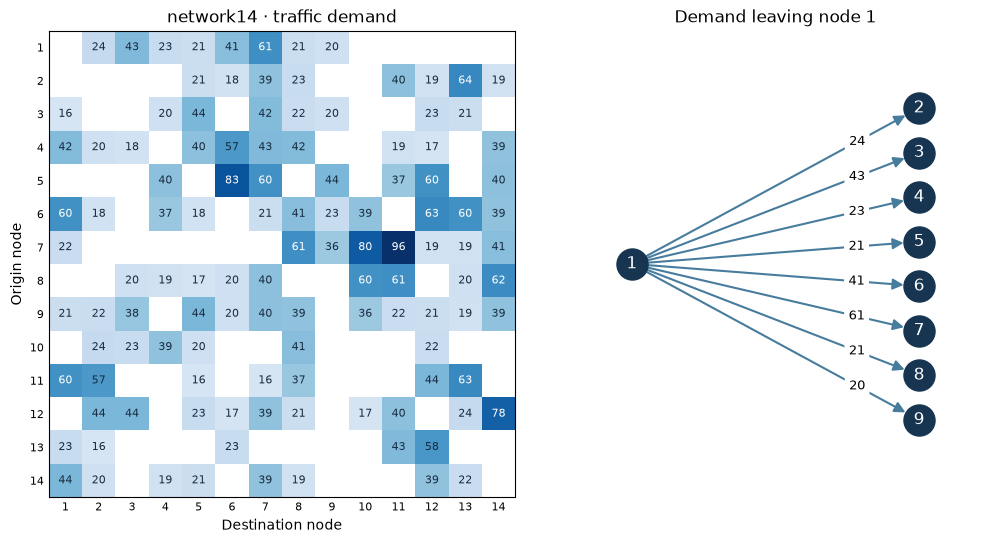

In [28]:
instance = REPLAY.split("_")[0]
demand_matrix = load_network_demand(int(instance.removeprefix("network")))
node_ids = np.arange(1, len(demand_matrix) + 1)
fig, (matrix_ax, graph_ax) = plt.subplots(
    1, 2, figsize=(max(10, len(node_ids) * 0.65), max(4.8, len(node_ids) * 0.38)),
    gridspec_kw={"width_ratios": [1.25, 1]}, layout="constrained")

# Display every positive origin–destination pair in QOBLIB's one-based node numbering.
matrix_ax.imshow(np.ma.masked_equal(demand_matrix, 0), cmap="Blues", vmin=0, vmax=demand_matrix.max())
for i, j in zip(*np.nonzero(demand_matrix)):
    amount = demand_matrix[i, j]
    matrix_ax.text(j, i, str(amount), ha="center", va="center",
                   fontsize=8, color="white" if amount > 0.62 * demand_matrix.max() else "#172b40")
matrix_ax.set(xticks=node_ids - 1, xticklabels=node_ids, yticks=node_ids - 1, yticklabels=node_ids,
              xlabel="Destination node", ylabel="Origin node", title=f"{instance} · traffic demand")
matrix_ax.tick_params(length=0, labelsize=8)

# Unfold row 1 as a directed graph so the direction and units are explicit.
graph = nx.DiGraph()
graph.add_node(1)
graph.add_weighted_edges_from((1, int(j + 1), int(demand_matrix[0, j]))
                              for j in np.flatnonzero(demand_matrix[0]))
destinations = list(graph.successors(1))
positions = {1: (0, 0)}
positions.update({node: (1, y) for node, y in zip(destinations, np.linspace(1, -1, len(destinations)))})
nx.draw_networkx(graph, positions, ax=graph_ax, node_size=500, node_color="#173450",
                 font_color="white", edge_color="#477c9d", arrowsize=16, width=1.5)
nx.draw_networkx_edge_labels(graph, positions, ax=graph_ax,
                             edge_labels=nx.get_edge_attributes(graph, "weight"),
                             label_pos=0.8, rotate=False, font_size=9)
graph_ax.set_title("Demand leaving node 1")
graph_ax.margins(0.18)
graph_ax.set_axis_off()
plt.show()

## 2 · Generate candidate networks with QAOA

Each possible link becomes a yes/no decision. The evolved function `r3g128` rewards useful direct links and pairs of links that form two-hop routes. `build_qubo` adds penalties for breaking the degree rule. Together these form a QUBO, a scoring model for promising designs.

Divi splits this model into smaller blocks, runs the Quantum Approximate Optimization Algorithm (QAOA) on them, and combines the samples into complete candidate networks. The table lists the settings available for each instance. Its **LP budget** is the number of routing evaluations available in Section 3.

In [29]:
recipes = {
    "network11": ("network11_r3g128_c16p2loc_seed0.json", 10000),
    "network12": ("network12_r3g128_c20p2_seed0.json", 10000),
    "network13": ("network13_r3g128_seed0.json", 20000),
    "network14": ("network14_r3g128_seed1.json", 20000),
    "network15": ("network15_r3g128_seed0.json", 10000),
    "network16": ("network16_r3g128_seed1.json", 20000),
    "network17": ("network17_r3g128_seed1.json", 25000),
    "network18": ("network18_r3g128_seed1.json", 10000),
    "network19": ("network19_r3g128_seed1.json", 25000),
    "network20": ("network20_r3g128_seed1.json", 20000),
    "network21": ("network21_r3g128_c16p2loc_seed0.json", 10000),
    "network22": ("network22_r3g128_seed0.json", 20000),
    "network23": ("network23_r3g128_seed0.json", 20000),
    "network24": ("network24_r3g128_seed0.json", 25000),
}
table(["Instance", "Starting pool", "LP budget"],
      [[name, pool, f"{budget:,}"] for name, (pool, budget) in recipes.items()])

| Instance | Starting pool | LP budget |
| --- | --- | --- |
| network11 | network11_r3g128_c16p2loc_seed0.json | 10,000 |
| network12 | network12_r3g128_c20p2_seed0.json | 10,000 |
| network13 | network13_r3g128_seed0.json | 20,000 |
| network14 | network14_r3g128_seed1.json | 20,000 |
| network15 | network15_r3g128_seed0.json | 10,000 |
| network16 | network16_r3g128_seed1.json | 20,000 |
| network17 | network17_r3g128_seed1.json | 25,000 |
| network18 | network18_r3g128_seed1.json | 10,000 |
| network19 | network19_r3g128_seed1.json | 25,000 |
| network20 | network20_r3g128_seed1.json | 20,000 |
| network21 | network21_r3g128_c16p2loc_seed0.json | 10,000 |
| network22 | network22_r3g128_seed0.json | 20,000 |
| network23 | network23_r3g128_seed0.json | 20,000 |
| network24 | network24_r3g128_seed0.json | 25,000 |

In [30]:
def prepare_traffic(demand):
    traffic = np.maximum(np.asarray(demand, dtype=float), 0.0)
    np.fill_diagonal(traffic, 0.0)
    scale = float(traffic.max(initial=0.0)) or 1.0
    normalized = traffic / scale
    weights = -(0.75 * normalized + 0.25 * np.sqrt(normalized))
    linear = {arc: float(weights[arc]) for arc in qt.all_arcs(len(traffic))}
    return traffic, scale, normalized, linear

def relay_pressure(traffic):
    incident = np.maximum(traffic.sum(axis=0), traffic.sum(axis=1))
    scale = float(incident.max(initial=0.0)) or 1.0
    return np.maximum(0.65, incident / scale)


# Source: shinka_postproc/pools/hamiltonians/r3g128.py
def r3g128(demand):
    """Build direct-link and selectively pressure-discounted two-hop terms."""
    traffic, _, normalized, linear = prepare_traffic(demand)
    roots = np.sqrt(normalized)
    n = len(traffic)
    node_pressure = relay_pressure(traffic)

    positive = traffic[traffic > 0.0]
    cutoff = float(np.quantile(positive, 0.75)) if positive.size else 0.0
    quadratic = {}

    for i in range(n):
        for k in range(n):
            if i == k or traffic[i, k] <= 0.0:
                continue

            support = 0.70 * normalized[i, k] + 0.30 * roots[i, k]
            candidates = []
            for j in range(n):
                if j == i or j == k:
                    continue
                edge_pressure = normalized[i, j] + normalized[j, k]
                pressure = float(node_pressure[j])
                affinity = 0.25 + edge_pressure
                rank = affinity / (pressure ** 0.75)
                discount = pressure * (1.0 + 0.5 * edge_pressure)
                candidates.append((float(rank), j, float(discount)))

            candidates.sort(reverse=True)
            keep = min(len(candidates), 4 if traffic[i, k] >= cutoff else 2)
            selected = set()

            for position, (_, j, discount) in enumerate(candidates[:keep]):
                selected.add(j)
                rank_factor = 1.0 + 0.08 * (keep - position)
                weight = -0.46 * float(support) * rank_factor / discount
                first, second = (i, j), (j, k)
                key = (first, second) if first < second else (second, first)
                quadratic[key] = weight

            # Retain one alternative selected by the full-path model's
            # pressure discount, unless it was already selected by affinity.
            remaining = [candidate for candidate in candidates if candidate[1] not in selected]
            if remaining:
                _, j, discount = min(remaining, key=lambda candidate: (candidate[2], candidate[1]))
                first, second = (i, j), (j, k)
                key = (first, second) if first < second else (second, first)
                quadratic[key] = -0.30 * float(support) / discount

    return linear, quadratic, 1.25

# Source: shinka_postproc/make_pools.py

def build_qubo(demand, surrogate):
    """Combine the evolved traffic costs with QOBLIB's degree penalties."""
    linear, quadratic, penalty_weight = surrogate(demand)
    _, penalty, arcs = qt.build_network_qubo(demand)
    index = {arc: i for i, arc in enumerate(arcs)}
    scale = max(max(map(abs, linear.values()), default=0), max(map(abs, quadratic.values()), default=0), 1e-12)
    # Use the same variable order in the BQM and the sampled bitstrings.
    model = dimod.BinaryQuadraticModel({i: linear[arc] / scale for i, arc in enumerate(arcs)}, {}, 0.0, dimod.BINARY)
    model.add_quadratic_from((index[a], index[b], w / scale) for (a, b), w in quadratic.items())
    penalty.scale(penalty_weight)
    model.update(penalty)
    model.normalize()
    return model, arcs

In [31]:
# Source: shinka_postproc/make_pools.py
def sample_partitioned_qaoa(bqm, cluster_size: int, seed: int, states: int, layers: int, shots: int,
                            population: int, iterations: int, backend_name: str):

    if backend_name == "local":
        backend = MaestroSimulator(shots=shots, force_sampling=False)
    elif backend_name == "cloud":
        backend = QoroService(job_config=JobConfig(
            simulator_cluster="qoro_maestro", shots=shots, force_sampling=False))
    else:
        raise ValueError("QAOA_BACKEND must be 'local' or 'cloud'.")
    problem = BinaryOptimizationProblem(
        bqm,
        decomposer=CommunityDecomposer(QUBOPartitioningConfig(max_n_variables_per_cluster=cluster_size)),
        composer=hybrid.SplatComposer(),
        local_search=True,
    )
    ensemble = PartitioningProgramEnsemble(
        problem=problem, quantum_routine="qaoa", n_layers=layers,
        optimizer=MonteCarloOptimizer(population_size=population), max_iterations=iterations, backend=backend, seed=seed,
    )
    ensemble.run()
    beam = max(100, states)
    tops = ensemble.get_top_solutions(n=states, strategy=BeamSearchStrategy(beam_width=beam, n_partition_candidates=10))
    return [(dict(zip(bqm.variables, sol)), float(energy)) for sol, energy in tops], ensemble.total_circuit_count

### Sample or load the starting pool

The output reports how many **circuits** produced how many **candidate networks**. The candidate count is `len(starts)`, the size of the pool passed to Section 3. **First repaired candidate** scores one example from this pool.

In [32]:
pool_name, budget = recipes[REPLAY]
pool = read_json(DATA / "pools" / pool_name)
size = int(pool["instance"][-2:])
traffic = load_network_demand(size)
bqm, arc_order = build_qubo(traffic, r3g128)
settings = pool.get("setup", {})  # Original make_pools.py defaults for early pools.
block_size = settings.get("cluster_size", 12)
print(f"{REPLAY}: {bqm.num_variables} possible links, up to {block_size} qubits per block.")
if FRESH_QAOA:
    np.random.seed(pool["seed"])
    samples, circuits = sample_partitioned_qaoa(
        bqm, block_size, pool["seed"], settings.get("states", 200), settings.get("layers", 2),
        settings.get("shots", 10000), settings.get("mc_population", 50), settings.get("mc_iterations", 10),
        backend_name=QAOA_BACKEND)
    starts = [qt.decode_topology(bits, arc_order) for bits, _ in samples]
    print(f"Fresh {QAOA_BACKEND} QAOA: {circuits:,} circuits, {len(starts)} candidates.")
else:
    starts = starts_from(pool)
    print(f"Archived QAOA: {pool['circuits']:,} circuits, {len(starts)} candidates.")
first = qt.repair_topology(size, starts[0], traffic)
print(f"First repaired candidate: {qt.route_min_congestion(traffic, first).objective:,.0f}")

Workflow                                                                         • Success! ✅  (Round 1 — 21   
                                                                                    programs)                      
   Submitting circuits                ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21/21 0:00:01  • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (1050 circuits, 21 programs)                                               • Success! ✅                  
■  Batch (21 circuits, 21 programs)                                                 • Success! ✅                  

Fresh cloud QAOA: 10,521 circuits, 200 candidates.
First repaired candidate: 426,834


## 3 · Improve the candidates with classical search

`improve_gen49` repairs candidate networks to satisfy the degree rule and selects several diverse starting points. It swaps links and uses a linear program (LP) to route traffic and measure the busiest link. The scoring helper (the oracle) caches each network’s result, counts LP solves against the budget, and records the best network it has scored.

ShinkaEvolve produced both `r3g128` and `improve_gen49` during development. This notebook executes the resulting Python functions.

In [33]:
# Routing oracle used by improve_gen49
class BudgetExhausted(BaseException):
    """Raised by tools.lp / tools.lp_detail once the LP budget is spent.

    A BaseException, so a generic `except Exception` in evolved code cannot swallow it."""


def _key(arcs) -> tuple:
    return tuple(sorted((int(i), int(j)) for i, j in arcs))


class Tools:
    def __init__(self, demand: np.ndarray, lp_budget: int, energy_terms=None):
        self.n = int(len(demand))
        self._demand = np.array(demand, dtype=np.int64)
        self._budget = int(lp_budget)
        self._used = 0
        self._cache: dict[tuple, dict] = {}
        self._best_score = math.inf
        self._best_arcs: tuple | None = None
        self._energy_terms = energy_terms  # (linear dict, quadratic dict) of the frozen Hamiltonian

    # ------------------------------------------------------------------ budget
    @property
    def lp_calls_used(self) -> int:
        return self._used

    @property
    def lp_calls_left(self) -> int:
        return self._budget - self._used

    # ------------------------------------------------------------------ free helpers
    def is_valid(self, arcs) -> bool:
        """Every node has exactly 2 outgoing and 2 incoming links, no self-loops."""
        return qt.is_valid_topology(self.n, _key(arcs))

    def repair(self, arcs) -> list[tuple[int, int]]:
        """Closest valid network: keeps as many of `arcs` as possible (exact matching, free)."""
        return qt.repair_topology(self.n, _key(arcs), self._demand)

    def energy(self, arcs) -> float:
        """Frozen Hamiltonian's surrogate energy of a link set (free, lower = predicted better)."""
        lin, quad = self._energy_terms
        s = set(_key(arcs))
        return float(sum(lin.get(a, 0.0) for a in s) + sum(w for (a, b), w in quad.items() if a in s and b in s))

    def is_cached(self, arcs) -> bool:
        """True if this network was already scored (scoring it again is free)."""
        return _key(arcs) in self._cache

    # ------------------------------------------------------------------ LP (budgeted)
    def lp_detail(self, arcs) -> dict:
        """Route all traffic on a valid network. One LP call unless cached.

        Returns {"score": QOBLIB objective (max link load, lower is better),
                 "loads": {link: total flow on it},
                 "prices": {link: dual price of its capacity, > 0 only on bottleneck links}}.
        Invalid networks return score = inf at no cost.
        """
        key = _key(arcs)
        if key in self._cache:
            return self._copy(self._cache[key])
        if not qt.is_valid_topology(self.n, key):
            return {"score": math.inf, "loads": {}, "prices": {}}
        if self._used >= self._budget:
            raise BudgetExhausted(f"LP budget of {self._budget} calls spent")
        self._used += 1
        var, c, A_ub, A_eq, b_eq = qt._routing_lp(self._demand, list(key))
        res = linprog(c, A_ub=A_ub, b_ub=np.zeros(A_ub.shape[0]), A_eq=A_eq, b_eq=b_eq,
                      bounds=(0, None), method="highs")
        if res.status != 0:
            out = {"score": math.inf, "loads": {}, "prices": {}}
        else:
            flows = res.x
            loads = {a: 0.0 for a in key}
            for (k, idx), col in var.items():
                loads[key[idx]] += float(flows[col])
            prices = {a: float(-res.ineqlin.marginals[idx]) for idx, a in enumerate(key)}
            out = {"score": float(math.ceil(res.fun - 1e-6)), "loads": loads, "prices": prices}
        self._cache[key] = out
        if out["score"] < self._best_score:
            self._best_score, self._best_arcs = out["score"], key
        return self._copy(out)

    @staticmethod
    def _copy(out: dict) -> dict:
        return {"score": out["score"], "loads": dict(out["loads"]), "prices": dict(out["prices"])}

    def lp(self, arcs) -> float:
        """Score of a valid network (max link load). One LP call unless cached; inf if invalid."""
        return self.lp_detail(arcs)["score"]

    # ------------------------------------------------------------------ evaluator side
    def certified_best(self) -> tuple[float, tuple | None]:
        return self._best_score, self._best_arcs

In [34]:
# Source: submit/code/postproc/init_run1_gen49.py
def improve_gen49(demand, candidates, tools, rng):
    """Search repaired QAOA networks using a surrogate-screened diverse archive."""
    n = tools.n
    seen = {}
    best_net = None
    best_score = float("inf")
    parent_stalls = {}

    def canon(arcs):
        return tuple(sorted(tuple(map(int, a)) for a in arcs))

    def evaluate(net):
        """Score once locally; budget exhaustion is allowed to reach the caller."""
        nonlocal best_net, best_score
        net = canon(net)
        if net not in seen:
            seen[net] = tools.lp(net)
        s = seen[net]
        if s < best_score:
            best_net, best_score = net, s
        return s

    def energy(net):
        try:
            return float(tools.energy(net))
        except Exception:
            return 0.0

    def distance(a, b):
        return len(set(a) ^ set(b))

    def choose_starts(repaired, limit):
        """Prefer low surrogate energy, while retaining topological variety."""
        ordered = sorted(repaired, key=energy)
        chosen = []
        for net in ordered:
            if all(distance(net, old) >= 4 for old in chosen):
                chosen.append(net)
            if len(chosen) >= limit:
                break
        for net in ordered:
            if len(chosen) >= limit:
                break
            if net not in chosen:
                chosen.append(net)
        return chosen

    # Repair all raw samples for free, then seed the search with a compact,
    # energy-ranked but diversity-aware subset.
    repaired = set()
    for cand in candidates:
        try:
            net = canon(tools.repair(cand))
            if tools.is_valid(net):
                repaired.add(net)
        except Exception:
            continue

    if not repaired:
        try:
            net = canon(tools.repair([]))
            if tools.is_valid(net):
                repaired.add(net)
        except Exception:
            return []

    initial = choose_starts(repaired, min(30, len(repaired)))
    for net in initial:
        if tools.lp_calls_left <= 0:
            break
        try:
            evaluate(net)
        except Exception as exc:
            if type(exc).__name__ == "BudgetExhausted":
                break
            continue

    if not seen:
        return list(initial[0])

    def archive():
        """Keep excellent networks and the best representatives of distinct regions."""
        ranked = sorted(seen, key=seen.get)
        out = []
        for net in ranked:
            if all(distance(net, old) >= 4 for old in out):
                out.append(net)
            if len(out) >= 24:
                break
        for net in ranked:
            if len(out) >= 32:
                break
            if net not in out:
                out.append(net)
        return out

    def select_parent(pop):
        """Mix elite exploitation with sampling from diverse archived networks."""
        if not pop:
            return best_net
        if rng.random() < 0.48:
            return pop[int(rng.integers(min(6, len(pop))))]
        return pop[int(rng.integers(len(pop)))]

    def switch(net, p, q):
        """Swap the destinations of two links, preserving all degrees."""
        arcs = list(net)
        (a, b), (c, d) = arcs[p], arcs[q]
        if a == d or c == b:
            return None
        cur = set(net)
        if (a, d) in cur or (c, b) in cur:
            return None
        cur.remove((a, b))
        cur.remove((c, d))
        cur.add((a, d))
        cur.add((c, b))
        return tuple(sorted(cur))

    def make_moves(net, detail):
        """Build a focused two-switch neighborhood plus sampled rotations and kicks."""
        arcs = list(net)
        current = set(net)
        moves = set()

        prices = detail.get("prices", {}) if detail else {}
        hot = {tuple(map(int, a)) for a, p in prices.items() if p > 0}
        if not hot and detail:
            loads = detail.get("loads", {})
            ranked_loads = sorted(
                ((float(v), tuple(map(int, a))) for a, v in loads.items()),
                reverse=True,
            )
            hot = {a for _, a in ranked_loads[:6]}

        # Exhaustively explore swaps involving at least one critical link.
        for p in range(len(arcs)):
            for q in range(p + 1, len(arcs)):
                if hot and arcs[p] not in hot and arcs[q] not in hot:
                    continue
                cand = switch(net, p, q)
                if cand is not None:
                    moves.add(cand)

        # Add non-focused swaps so that dual degeneracy cannot trap the search.
        for _ in range(70):
            if len(arcs) < 2:
                break
            p = int(rng.integers(len(arcs)))
            q = int(rng.integers(len(arcs) - 1))
            if q >= p:
                q += 1
            cand = switch(net, p, q)
            if cand is not None:
                moves.add(cand)

        # Escalate rotation sampling for parents whose neighborhoods have stalled.
        # Rotations preserve degrees and can cross barriers that two-switches miss.
        if len(arcs) >= 3:
            stalls = parent_stalls.get(net, 0)
            rotation_trials = min(350, 70 * (1 + stalls // 3))
            for _ in range(rotation_trials):
                ids = rng.choice(len(arcs), size=3, replace=False)
                (a, b), (c, d), (e, f) = (arcs[int(i)] for i in ids)
                old = {(a, b), (c, d), (e, f)}
                if hot and not (old & hot):
                    continue
                for new in (
                    {(a, d), (c, f), (e, b)},
                    {(a, f), (c, b), (e, d)},
                ):
                    if len(new) != 3 or any(x == y for x, y in new):
                        continue
                    if new & (current - old):
                        continue
                    cand = tuple(sorted((current - old) | new))
                    moves.add(cand)

        # Occasional multi-switch kicks broaden the neighborhood beyond one step.
        for _ in range(24):
            cur = set(net)
            for _ in range(2 + int(rng.integers(4))):
                arcs_now = list(cur)
                if len(arcs_now) < 2:
                    break
                p, q = rng.choice(len(arcs_now), size=2, replace=False)
                a, b = arcs_now[int(p)]
                c, d = arcs_now[int(q)]
                if a == d or c == b or (a, d) in cur or (c, b) in cur:
                    continue
                cur.remove((a, b))
                cur.remove((c, d))
                cur.add((a, d))
                cur.add((c, b))
            cand = tuple(sorted(cur))
            if cand != net:
                moves.add(cand)

        return [m for m in moves if m != net and tools.is_valid(m)]

    def screen_batch(moves, parent, batch_size=9):
        """Use surrogate ranking and topology distance to select an LP batch."""
        fresh = [
            m for m in moves
            if m not in seen and not tools.is_cached(m)
        ]
        if not fresh:
            return []

        base_e = energy(parent)
        ranked = []
        for net in fresh:
            ranked.append((energy(net) - base_e, net))
        ranked.sort(key=lambda item: item[0])

        selected = []
        # First take good-energy moves that are not all tiny variants of one another.
        for _, net in ranked:
            if all(distance(net, old) >= 2 for old in selected):
                selected.append(net)
            if len(selected) >= min(6, batch_size):
                break

        # Fill remaining slots with the best surrogate-ranked moves.
        for _, net in ranked:
            if len(selected) >= batch_size:
                break
            if net not in selected:
                selected.append(net)

        # Reserve a little batch capacity for tail exploration.
        tail = [net for _, net in ranked if net not in selected]
        if tail and len(selected) >= 4 and len(selected) < batch_size:
            rng.shuffle(tail)
            selected.extend(tail[:batch_size - len(selected)])
        return selected[:batch_size]

    # A bounded archive drives a sequence of short, diverse neighborhood searches.
    rounds = 0
    while tools.lp_calls_left > 0:
        rounds += 1
        pop = archive()
        parent = select_parent(pop)
        if parent is None:
            break

        try:
            detail = tools.lp_detail(parent)
        except Exception:
            detail = None

        moves = make_moves(parent, detail)
        batch = screen_batch(moves, parent)

        # If a neighborhood has already been exhausted, perturb another archive
        # member rather than repeatedly revisiting the same parent.
        if not batch:
            alternatives = [x for x in pop if x != parent]
            if alternatives:
                parent = alternatives[int(rng.integers(len(alternatives)))]
                try:
                    detail = tools.lp_detail(parent)
                except Exception:
                    detail = None
                batch = screen_batch(make_moves(parent, detail), parent)

        if not batch:
            # A final random degree-preserving kick guarantees progress when possible.
            for _ in range(40):
                cur = set(parent)
                arcs = list(cur)
                for _ in range(3 + int(rng.integers(4))):
                    p, q = rng.choice(len(arcs), size=2, replace=False)
                    a, b = arcs[int(p)]
                    c, d = arcs[int(q)]
                    if a == d or c == b or (a, d) in cur or (c, b) in cur:
                        continue
                    cur.remove((a, b))
                    cur.remove((c, d))
                    cur.add((a, d))
                    cur.add((c, b))
                    arcs = list(cur)
                kicked = tuple(sorted(cur))
                if kicked != parent and kicked not in seen and not tools.is_cached(kicked):
                    batch = [kicked]
                    break

        if not batch:
            # All available moves may be cached; avoid an unbounded spin.
            if rounds > 10000:
                break
            continue

        parent_score = seen.get(parent, float("inf"))
        for net in batch:
            if tools.lp_calls_left <= 0:
                break
            try:
                evaluate(net)
            except Exception as exc:
                if type(exc).__name__ == "BudgetExhausted":
                    return list(best_net) if best_net is not None else []
                continue

        batch_best = min((seen.get(net, float("inf")) for net in batch), default=float("inf"))
        if batch_best < parent_score:
            parent_stalls[parent] = 0
        else:
            parent_stalls[parent] = parent_stalls.get(parent, 0) + 1

    return list(best_net) if best_net is not None else []

In [ ]:
def run_search(demand, candidates, budget, seed=0):
    linear, quadratic, _ = r3g128(demand)
    tools = Tools(demand, budget, (linear, quadratic))
    returned = None
    try:
        returned = improve_gen49(demand.copy(), candidates, tools, np.random.default_rng(seed))
    except BudgetExhausted:
        pass
    score, arcs = tools.certified_best()
    # Original run_postproc wrapper also checks a topology returned before budget exhaustion.
    if returned is not None and qt.is_valid_topology(len(demand), returned):
        final_score = qt.route_min_congestion(demand, returned).objective
        if final_score < score:
            score, arcs = final_score, tuple(sorted(returned))
    return score, arcs, tools.lp_calls_used

score, links, calls = run_search(traffic, starts, budget)
print(f"{REPLAY}: {calls:,} LP calls, best routing score {score:,.0f}")

### Verify the winner against its integer flows

The next cell routes integer flows on the winning links, writes a solution file, and checks it with `qoblib_tools`. **LP score** and **New integer-flow file** must agree. **Archived submission** gives the historical result for comparison. It may have used a different candidate pool or search checkpoint.

In [ ]:
routing = qt.route_integral(traffic, links)
reference_path = DATA / "solutions" / f"network{size:02d}.sol"
with TemporaryDirectory() as folder:
    generated = Path(folder) / f"network{size:02d}.sol"
    qt.write_network_solution(generated, size, routing)
    valid, generated_score, reason = qt.check_network_solution(generated, size, traffic)
assert valid and generated_score == score, (reason, generated_score, score)
_, reference_score, _ = qt.check_network_solution(reference_path, size, traffic)
table(["Instance", "LP score", "New integer-flow file", "Archived submission"],
      [[REPLAY, f"{score:,.0f}", f"{generated_score:,}", f"{reference_score:,}"]])

## 4 · Historical experiment on QAOA starting points

This table loads the team's earlier network12 experiment. It compares the same classical search starting from two held-out QAOA pools and five sets of random networks. Each percentage is a gap above the benchmark. Smaller is better.

In [ ]:
report = DATA / "quantum_value_run1_heldout_only.txt"
budget_rows = [line.split("|") for line in report.read_text().splitlines()
               if line.partition("|")[0].strip().isdigit()]
table(["LP budget", "QAOA mean (range)", "Random mean (range)"], budget_rows)

At 500 LP calls, the mean gaps were **3.15%** for QAOA and **5.70%** for random starts. At 2,000 calls they narrowed to **2.06%** and **2.70%**, with overlapping ranges.

## 5 · Verify the archived submissions

This cell checks the 15 solution files submitted during the hackathon. For each file it verifies the integer flows, recomputes the routing score, and compares the score with the benchmark used in the pitch. A negative gap means the submission improved on that benchmark.

In [ ]:
records = read_json(DATA / "records.json")
result_rows = []
gaps = []
for size in range(10, 25):
    name = f"network{size:02d}"
    record = records["overall"][name]
    path = DATA / "solutions" / f"{name}.sol"
    traffic = load_network_demand(size)
    valid, score, reason = qt.check_network_solution(path, size, traffic)
    claimed, links, _ = qt.read_network_solution(path)
    lp_score = qt.route_min_congestion(traffic, links).objective
    assert valid and claimed == score == lp_score == record["score"], (name, reason, score, lp_score)
    gap = 100 * (score / record["bkv"] - 1)
    gaps.append(gap)
    qaoa_match = records["quantum"].get(name, {}).get("score") == score
    result_rows.append([name, f"{record['bkv']:,}", f"{score:,}", f"{gap:+.2f}%",
                        "Yes" if qaoa_match else "No"])
table(["Instance", "Benchmark", "Verified score", "Gap", "QAOA-seeded run attained score?"], result_rows)
print(f"{sum(g < 0 for g in gaps)} improvements and {gaps.count(0)} ties.")

The strongest improvement was **3.42% on network23**. On network24, peak load fell from **663,688 to 659,539** checker units.

## Solved network from this run

Each arrow is a link selected in Section 3. Orange marks the links carrying the most traffic. The title gives their peak load in demand units, equal to the verified score divided by 1,000. Compare this graph with Section 1 to see how the selected links serve the original requests.

In [ ]:
solution_graph = nx.DiGraph()
solution_graph.add_edges_from(routing.arcs, load=0)
for (_, origin, destination), flow in routing.flows.items():
    solution_graph[origin][destination]["load"] += flow

peak = max(nx.get_edge_attributes(solution_graph, "load").values())
assert peak == routing.objective
# Draw the busiest links last so their arrows remain visible at crossings.
edges = sorted(solution_graph.edges, key=lambda edge: solution_graph.edges[edge]["load"])
at_peak = [solution_graph.edges[edge]["load"] == peak for edge in edges]
positions = nx.kamada_kawai_layout(solution_graph.to_undirected(),
                                   pos=nx.circular_layout(sorted(solution_graph)))
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
nx.draw_networkx(solution_graph, positions, ax=ax, edgelist=edges,
                 labels={node: node + 1 for node in solution_graph},
                 node_color="#173450", node_size=440, font_color="white",
                 edge_color=["#c54b16" if hot else "#8099b0" for hot in at_peak],
                 width=[2.8 if hot else 1.35 for hot in at_peak], arrowsize=15,
                 connectionstyle="arc3,rad=0.12")
ax.set_title(f"{REPLAY} · {len(edges)} directed links · peak load {peak / qt.INTSCALE:,.3f}")
ax.margins(0.15)
ax.set_aspect("equal")
ax.set_axis_off()
plt.show()